
# Lab 7: Fast Fourier Transform (FFT)

 **Example 1** : Chord - musical sound: Do mayor. Done in class.

![Do mayor](https://upload.wikimedia.org/wikipedia/commons/7/79/Major_chord_on_C.png)

Load the Nota_CM_piano.mp3 file from a Do mayor sound:
1. Do the FFT using scipy and Numpy rutines (see notebook)
2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?


 **Exercise 1** : Do the FFT for an Imagen

Choose an Imagen

1. Do the FFT using scipy (see notebook)
2. Used the rutine created in class `FT(x,y)`. Modify it and do the FT to the signal. Do you get the same results?
3. Do the inverse FFT and reconstruc the original imagene. <br> Do you get a similar result? Compare the original and the reconstructed signal.


In [18]:
import time
import numpy as np
import matplotlib.pyplot as plt
import librosa                         # para leer el mp3
from scipy.fft import fft, fftfreq, fft2, ifft2
from scipy.signal import find_peaks, decimate
from PIL import Image                  # para leer la imagen
import pandas as pd
from scipy import interpolate, integrate

Frecuencia de muestreo: 44100 Hz
Número de muestras: 152064
Duración: 3.45 s


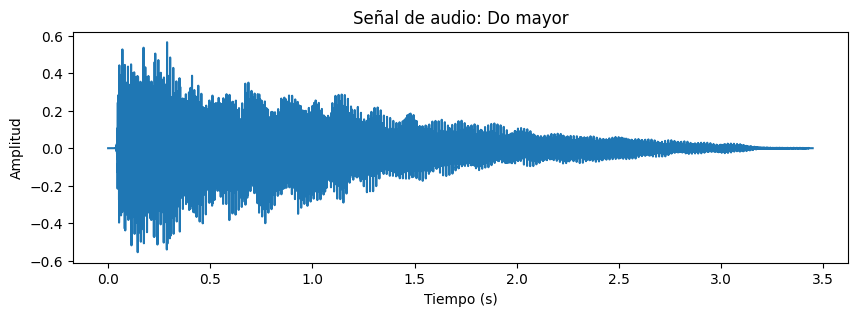

In [19]:
archivo = "/content/Nota_CM_piano.mp3"

y, sr = librosa.load(archivo, sr=None, mono=True)

N = len(y)
t = np.arange(N) / sr   # vector de tiempo en segundos

print(f"Frecuencia de muestreo: {sr} Hz")
print(f"Número de muestras: {N}")
print(f"Duración: {N/sr:.2f} s")

plt.figure(figsize=(10, 3))
plt.plot(t, y)
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.title("Señal de audio: Do mayor")
plt.show()

scipy y numpy iguales: False


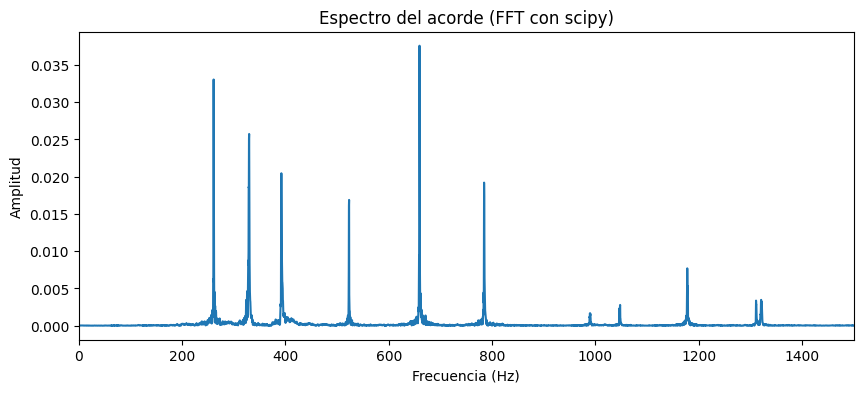

In [20]:
# --- FFT con scipy ---
Y_scipy = fft(y)
f = fftfreq(N, d=1/sr)          # eje de frecuencias en Hz

# --- FFT con numpy ---
Y_numpy = np.fft.fft(y)

# ¿Dan lo mismo?
print("scipy y numpy iguales:", np.allclose(Y_scipy, Y_numpy))

# Nos quedamos con las frecuencias positivas (la otra mitad es el espejo)
mitad = N // 2
frecuencias = f[:mitad]
amplitud = 2 * np.abs(Y_scipy[:mitad]) / N    # amplitud normalizada

plt.figure(figsize=(10, 4))
plt.plot(frecuencias, amplitud)
plt.xlim(0, 1500)
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.title("Espectro del acorde (FFT con scipy)")
plt.show()

In [21]:
def nombre_nota(freq):
    """Convierte una frecuencia en Hz al nombre de la nota más cercana."""
    nombres = ["Do", "Do#", "Re", "Re#", "Mi", "Fa", "Fa#", "Sol", "Sol#", "La", "La#", "Si"]
    midi = int(round(69 + 12 * np.log2(freq / 440)))
    return nombres[midi % 12] + str(midi // 12 - 1)

df = sr / N                                   # resolución en frecuencia
picos, _ = find_peaks(amplitud, height=0.1 * amplitud.max(), distance=int(15 / df))

print("Picos principales encontrados:")
for p in picos:
    if frecuencias[p] < 2000:
        print(f"  {frecuencias[p]:8.1f} Hz  ->  {nombre_nota(frecuencias[p])}")

Picos principales encontrados:
     261.0 Hz  ->  Do4
     329.7 Hz  ->  Mi4
     392.1 Hz  ->  Sol4
     523.2 Hz  ->  Do5
     659.5 Hz  ->  Mi5
     784.5 Hz  ->  Sol5
    1177.7 Hz  ->  Re6
    1576.2 Hz  ->  Sol6
    1971.5 Hz  ->  Si6
    1990.0 Hz  ->  Si6


In [22]:
# Base de Fourier continua
def g(t, w):
    return 1./(2*np.pi) * np.exp(-1j*2*np.pi*w*t)

def FT_complejo(x, y, w):
    """
    Integral de y(t)*g(t,w) para cada frecuencia w.
    Modificación respecto a clase: w es un parámetro, y la integral
    se calcula como suma (y es discreta): integral ≈ suma(y*g)*dx
    """
    dx = x[1] - x[0]
    kernel = g(x.reshape(1, -1), np.asarray(w).reshape(-1, 1))  # (n_frecuencias, n_muestras)
    return (kernel @ y) * dx

def FT(x, y, w):
    """Igual que en clase: devuelve un DataFrame con w, Re, Im, AMP y ANG."""
    F = FT_complejo(x, y, w)
    return pd.DataFrame({'w': w, 'ReTw': F.real, 'ImTw': F.imag,
                         'AMP': np.abs(F), 'ANG': np.angle(F)})

Tiempo FT: 0.290 s
Diferencia máxima en amplitud: 1.1108275150412128e-10


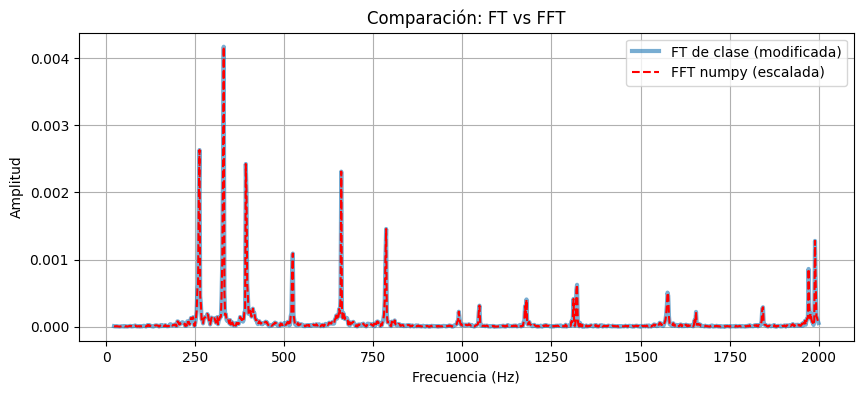

In [23]:
# Fragmento de 0.5 s con la frecuencia de muestreo dividida por 4
factor = 4
segmento = decimate(y[:int(0.5 * sr)], factor)
sr2 = sr / factor
x_seg = np.arange(len(segmento)) / sr2
dt = x_seg[1] - x_seg[0]
N_seg = len(segmento)

#FFT de numpy sobre el mismo fragmento
Y_np = np.fft.rfft(segmento)
f_np = np.fft.rfftfreq(N_seg, d=dt)

#Frecuencias de comparacion(20 a 2000 Hz)
rango = (f_np >= 20) & (f_np <= 2000)
w = f_np[rango]

# FT de clase modificada
t0 = time.time()
df_FT = FT(x_seg, segmento, w)
print(f"Tiempo FT: {time.time() - t0:.3f} s")


Y_np_esc = Y_np[rango] * dt / (2 * np.pi)

print("Diferencia máxima en amplitud:", np.max(np.abs(df_FT.AMP - np.abs(Y_np_esc))))

plt.figure(figsize=(10, 4))
plt.plot(df_FT.w, df_FT.AMP, label="FT de clase (modificada)", linewidth=3, alpha=0.6)
plt.plot(w, np.abs(Y_np_esc), "--", color="red", label="FFT numpy (escalada)")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.title("Comparación: FT vs FFT")
plt.legend()
plt.grid()
plt.show()

#**Exercise #2**

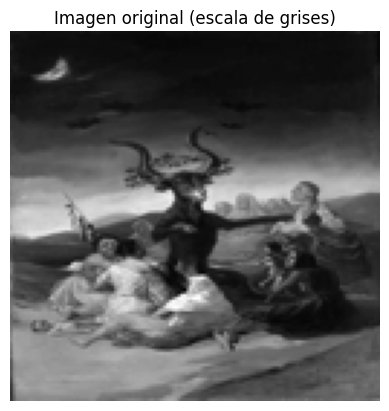

In [30]:
ruta_imagen = "/content/goya.jpg"
tamano = 128                  # se reduce a 128x128 para que la FT manual no tarde

try:
    img = Image.open(ruta_imagen).convert("L").resize((tamano, tamano))
    img = np.array(img, dtype=float)
except FileNotFoundError:
    # Si no encuentra el archivo, usa una imagen sintética para que el código funcione
    print("No se encontró la imagen, se usa una imagen de prueba.")
    img = np.zeros((tamano, tamano))
    img[30:90, 40:100] = 200
    yy, xx = np.ogrid[:tamano, :tamano]
    img[(yy - 50)**2 + (xx - 50)**2 < 400] = 255

plt.imshow(img, cmap="gray")
plt.title("Imagen original (escala de grises)")
plt.axis("off")
plt.show()

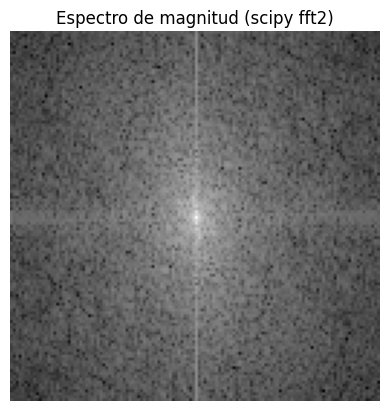

Tiempo FT2D: 0.015 s
¿es el mismo resultado que con scipy? True
Diferencia máxima: 6.040996356783849e-09


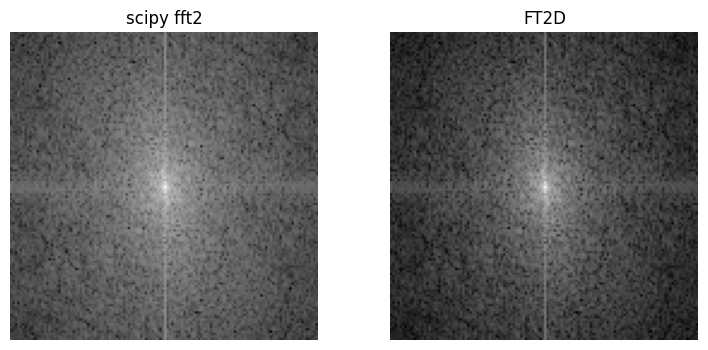

In [26]:
def FT2D(imagen):
    """FT 2D usando la FT de clase: primero sobre columnas, luego sobre filas."""
    filas, cols = imagen.shape
    F = FT_complejo(np.arange(filas), imagen, np.arange(filas) / filas)   # columnas
    F = FT_complejo(np.arange(cols), F.T, np.arange(cols) / cols).T       # filas
    return F

t0 = time.time()
F_propia = FT2D(img)
print(f"Tiempo FT2D: {time.time() - t0:.3f} s")


F_propia_esc = F_propia * (2 * np.pi)**2
print("¿es el mismo resultado que con scipy?", np.allclose(F_propia_esc, F_scipy))
print("Diferencia máxima:", np.max(np.abs(F_propia_esc - F_scipy)))

espectro_propio = np.log(1 + np.abs(np.fft.fftshift(F_propia)))

fig, ejes = plt.subplots(1, 2, figsize=(9, 4))
ejes[0].imshow(espectro_scipy, cmap="gray"); ejes[0].set_title("scipy fft2")
ejes[1].imshow(espectro_propio, cmap="gray"); ejes[1].set_title("FT2D")
for e in ejes: e.axis("off")
plt.show()

Error máximo (scipy): 5.684341886080802e-14
Error máximo (propia): 5.4924953474255744e-12
¿Reconstrucción igual a la original? True


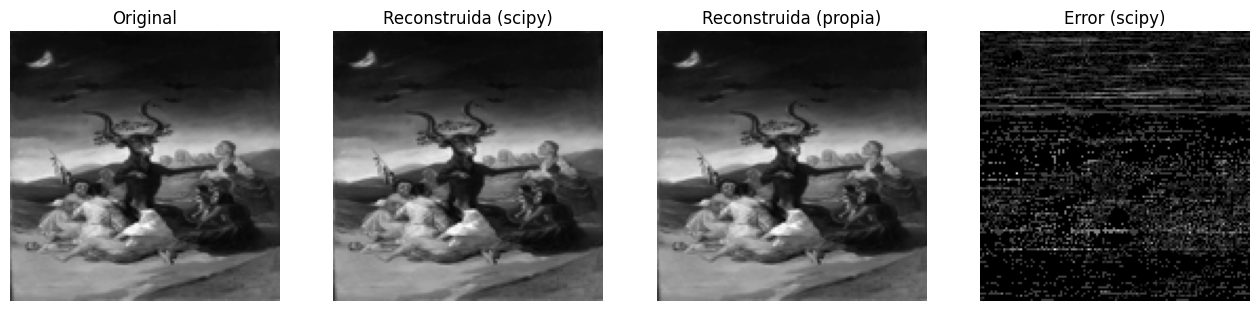

In [28]:
#inversa con scipy
img_rec_scipy = np.real(ifft2(F_scipy))

#inversa FFT
def IFT_complejo(w, F, x):
    dw = w[1] - w[0]
    kernel = np.exp(1j*2*np.pi * x.reshape(-1, 1) * w.reshape(1, -1))
    return 2*np.pi * (kernel @ F) * dw

def IFT2D(F):
    filas, cols = F.shape
    G = IFT_complejo(np.arange(filas)/filas, F, np.arange(filas))     # columnas
    G = IFT_complejo(np.arange(cols)/cols, G.T, np.arange(cols)).T    # filas
    return G

img_rec_propia = np.real(IFT2D(F_propia))

# comparación
error_scipy = np.abs(img - img_rec_scipy)
error_propia = np.abs(img - img_rec_propia)
print("Error máximo (scipy):", error_scipy.max())
print("Error máximo (propia):", error_propia.max())
print("¿Reconstrucción igual a la original?", np.allclose(img, img_rec_propia))

fig, ejes = plt.subplots(1, 4, figsize=(16, 4))
ejes[0].imshow(img, cmap="gray");            ejes[0].set_title("Original")
ejes[1].imshow(img_rec_scipy, cmap="gray");  ejes[1].set_title("Reconstruida (scipy)")
ejes[2].imshow(img_rec_propia, cmap="gray"); ejes[2].set_title("Reconstruida (propia)")

for e in ejes: e.axis("off")
plt.show()